# Supplemental Figure 5, Panel E

Gene set enrichment analysis using log2FC in nascent transcription IFN-gamma vs vehicle from PRO-seq. GSEA run on all GO:BP pathways in msigdbr, with top 10 pathways (ranked by NES) plotted.

*Output: PanelE_gsea.pdf*

# Setup

In [3]:
library(tidyverse)
library(RColorBrewer)
library(ggrastr)
library(here)
library(fgsea)
library(msigdbr)
here::i_am("figures/SuppFig5/PanelE/PanelE_GSEA.ipynb")
sessionInfo()

collapse_deg_duplicates <- function(df,
                                    gene_col = "gene",
                                    padj_col = "padj",
                                    lfc_col  = "log2FoldChange") {
  df %>%
    filter(!is.na(.data[[gene_col]])) %>%
    group_by(.data[[gene_col]]) %>%
    arrange(.data[[padj_col]], desc(abs(.data[[lfc_col]]))) %>%
    dplyr::slice(1) %>%
    ungroup()
}

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] msigdbr_7.5.1      fgsea_1.24.0       here_1.0.2         ggrastr_1.0.2     
 [5] RColorBrewer_1.1-3 lubridate_1.9.4    forcats_1.0.0      stringr_1.5.1     
 [9] dplyr_1.1.4        purrr_1.0.2        readr_2.1.5        tidyr_1.3.1       
[13] tibble_3.2.1       ggplot2_3.5.2      tidyvers

# Load gene sets

In [2]:
all_gene_sets = msigdbr(species = "Homo sapiens")
keeper.cats <- c("GO:BP")
all_gene_sets <- all_gene_sets[which(all_gene_sets$gs_subcat %in% keeper.cats),]
msigdbr_list = split(x = all_gene_sets$gene_symbol, f = all_gene_sets$gs_name)

# Load data

In [1]:
ifn <- read.delim(
    here("inputs","DEGs","GM12878","BAFinh_stimulus","PROseq","PRO_DEGs_IFN_Veh.tsv"),
    sep='\t')
ifn <- collapse_deg_duplicates(ifn)

# Extract ranking values (log2FCs)
stats <- ifn$log2FoldChange
names(stats) <- ifn$gene
stats <- na.omit(stats)

ERROR: Error in here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "PROseq", : could not find function "here"


# run GSEA

In [5]:
gsea_res <- fgsea(pathways=msigdbr_list, stats = stats)

Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are ties in the preranked stats (0.07% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”


Warning message in geom_point(shape = 21, size = 3, color = "black", width = 0.75):
“Ignoring unknown parameters: `width`”
Saving 7 x 3 in image


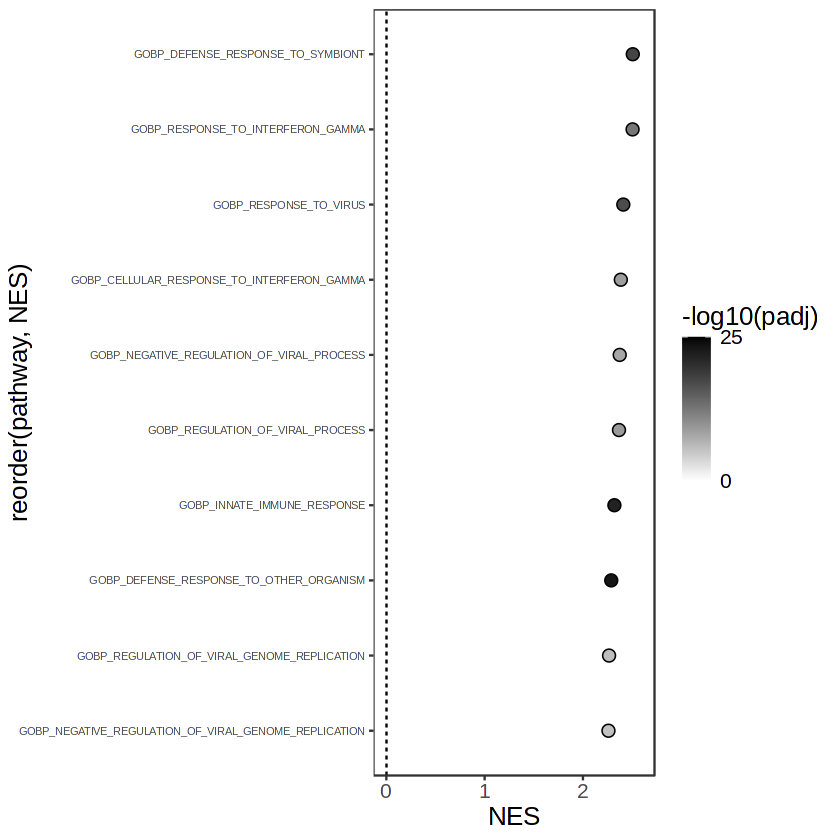

In [6]:
gsea_res %>% arrange(desc(NES)) %>%
    head(10) %>%
    ggplot(aes(y=reorder(pathway, NES), x=NES, fill=-log10(padj))) +
    theme_bw() + 
    geom_vline(xintercept=0, linetype=2) + 
    theme(axis.text.y=element_text(size=6), 
          panel.grid=element_blank(),
          text=element_text(size=15)) + 
    geom_point(shape=21, size=3, color="black") +
    scale_fill_gradient2(low="white", high="black", limits=c(0,25), breaks=c(0,25)) +
    xlim(0,2.6)
ggsave("PanelE_gsea.pdf", height=3)